# Explainable Cyber Threat Defense Workbench

## Can simple rules and explainable models identify attack-labeled network flows?

This **one-notebook MVP** profiles the data, compares three detection signals, trains three alternative models on shared inputs, evaluates alerts on a held-out set, and explains misses. The result is a research demonstration—not a live SOC tool.

We use the [UNSW-NB15 dataset](https://research.unsw.edu.au/projects/unsw-nb15-dataset), created in a cyber range with normal and simulated attack traffic. Its published training and testing CSVs contain 175,341 and 82,332 rows. We use the full published training split for model development and keep the published test split for the final check. The data has an unusually high proportion of attack labels, so alert precision here does **not** estimate precision in a production security queue.


## 1. Imports and data provenance

Place the two CSV files in `data/raw/` as described in the README. `attack_cat` is used only for the final missed-attack audit; `label` is the target; `id` is a row identifier. None enters the model inputs.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import IsolationForest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier, DMatrix
from interpret.glassbox import ExplainableBoostingClassifier

SEED = 42
ROOT = Path.cwd()
TRAIN_PATH = ROOT / 'data/raw/UNSW_NB15_training-set.csv'
TEST_PATH = ROOT / 'data/raw/UNSW_NB15_testing-set.csv'
for path in [TRAIN_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}; see README.md for the source.')

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

print('Training SHA-256:', sha256(TRAIN_PATH))
print('Testing SHA-256: ', sha256(TEST_PATH))
train_all = pd.read_csv(TRAIN_PATH)
test_all = pd.read_csv(TEST_PATH)
assert train_all.columns.tolist() == test_all.columns.tolist()
assert set(train_all['label'].unique()) == {0, 1}
assert set(test_all['label'].unique()) == {0, 1}
print('Training:', train_all.shape, 'Testing:', test_all.shape)


Training SHA-256: bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa
Testing SHA-256:  734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559


Training: (175341, 45) Testing: (82332, 45)


## 2. Profile the data and labels

A row represents a summarized network flow. We will predict the binary attack label, then inspect which generated attack categories are missed. The benchmark's attack prevalence is part of the experiment and should always accompany its precision numbers.


,split,flows,attack_labeled,attack_rate,missing_cells
0,published train,175341,119341,0.680622,0
1,published test,82332,45332,0.550600,0


,train,test
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


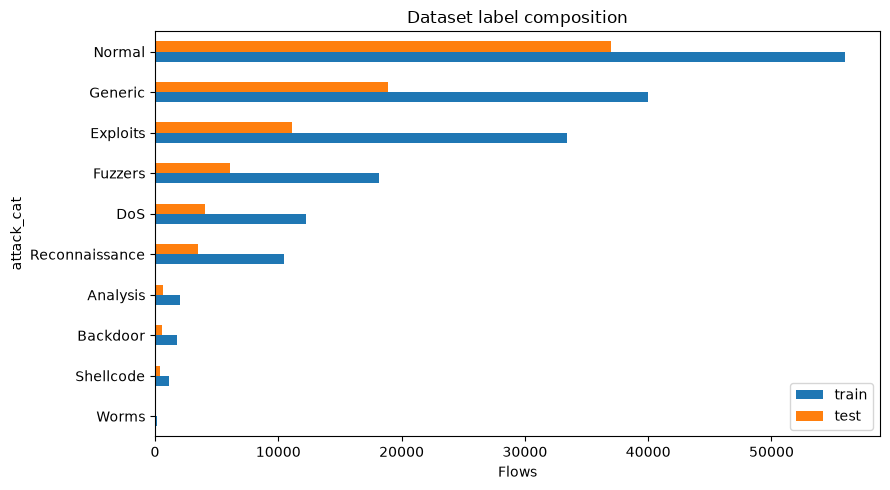

In [2]:
profile = pd.DataFrame({
    'split': ['published train', 'published test'],
    'flows': [len(train_all), len(test_all)],
    'attack_labeled': [int(train_all.label.sum()), int(test_all.label.sum())],
    'attack_rate': [train_all.label.mean(), test_all.label.mean()],
    'missing_cells': [int(train_all.isna().sum().sum()), int(test_all.isna().sum().sum())],
})
display(profile)
category_counts = pd.concat([
    train_all.attack_cat.value_counts().rename('train'),
    test_all.attack_cat.value_counts().rename('test'),
], axis=1).fillna(0).astype(int)
display(category_counts)
ax = category_counts.sort_values('train').plot(kind='barh', figsize=(9, 5), title='Dataset label composition')
ax.set_xlabel('Flows')
plt.tight_layout()
plt.show()


## 3. Audit duplicate feature rows and fix evaluation populations

The published split has many repeated feature rows. An exact copy of a model input in both train and test can make a holdout appear easier than it is. We identify exact matches using **all input columns** (excluding `id`, `label`, and `attack_cat`). The primary test result uses only test rows whose input fingerprint does not appear in the published training file. This removes exact input overlap; it does not establish independence between traffic sessions.

The published train/test CSVs have no event timestamp, so this MVP cannot make the chronological split used in the AML notebook. Within the published training file, a grouped random split keeps identical feature rows on one side of train/validation.


In [3]:
INPUT_COLUMNS = [c for c in train_all.columns if c not in {'id', 'attack_cat', 'label'}]
train_hash = pd.util.hash_pandas_object(train_all[INPUT_COLUMNS], index=False)
test_hash = pd.util.hash_pandas_object(test_all[INPUT_COLUMNS], index=False)
overlap = test_hash.isin(set(train_hash))
conflicting_train_groups = (train_all.assign(_hash=train_hash.to_numpy())
                            .groupby('_hash')['label'].nunique().gt(1).sum())
audit = pd.DataFrame({
    'measure': ['duplicate train rows', 'duplicate test rows',
                'test rows with input match in train', 'test rows retained for primary evaluation',
                'train input groups with conflicting labels'],
    'count': [int(train_hash.duplicated().sum()), int(test_hash.duplicated().sum()),
              int(overlap.sum()), int((~overlap).sum()), int(conflicting_train_groups)],
})
display(audit)
test = test_all.loc[~overlap].copy().reset_index(drop=True)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
fit_idx, val_idx = next(splitter.split(train_all, train_all.label, groups=train_hash))
fit = train_all.iloc[fit_idx].copy().reset_index(drop=True)
validation = train_all.iloc[val_idx].copy().reset_index(drop=True)
assert not set(train_hash.iloc[fit_idx]).intersection(set(train_hash.iloc[val_idx]))
display(pd.DataFrame({
    'period': ['fit', 'validation', 'primary test'],
    'flows': [len(fit), len(validation), len(test)],
    'attack_rate': [fit.label.mean(), validation.label.mean(), test.label.mean()],
}))


,measure,count
0,duplicate train rows,74301
1,duplicate test rows,28386
2,test rows with input match in train,8541
3,test rows retained for primary evaluation,73791
4,train input groups with conflicting labels,229


,period,flows,attack_rate
0,fit,140145,0.679782
1,validation,35196,0.683970
2,primary test,73791,0.518532


## 4. Define shared features

All three classifiers will see the same raw flow fields plus the three track signals below. We use a compact, readable subset of numeric traffic and recent-connection count fields, and three categorical fields. We do not use the generated attack category or row ID.


In [4]:
BASE_NUMERIC = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss', 'ct_srv_src', 'ct_dst_ltm',
    'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
]
CATEGORICAL = ['proto', 'service', 'state']
assert set(BASE_NUMERIC + CATEGORICAL).issubset(INPUT_COLUMNS)
assert fit[BASE_NUMERIC].ge(0).all().all()
print('Raw numeric features:', len(BASE_NUMERIC))
print('Categorical features:', CATEGORICAL)
display(pd.DataFrame([
    ('dur', 'Flow duration'),
    ('spkts / dpkts', 'Packets sent by source / destination'),
    ('sbytes / dbytes', 'Bytes sent by source / destination'),
    ('sttl / dttl', 'Time-to-live values in each direction'),
    ('ct_src_dport_ltm', 'Recent connections sharing source and destination port'),
    ('ct_dst_src_ltm', 'Recent connections sharing source and destination'),
    ('proto / service / state', 'Protocol, service, and connection state'),
], columns=['field', 'plain-language meaning']))


Raw numeric features: 17
Categorical features: ['proto', 'service', 'state']


,field,plain-language meaning
0,dur,Flow duration
1,spkts / dpkts,Packets sent by source / destination
2,sbytes / dbytes,Bytes sent by source / destination
3,sttl / dttl,Time-to-live values in each direction
4,ct_src_dport_ltm,Recent connections sharing source and destinat...
5,ct_dst_src_ltm,Recent connections sharing source and destination
6,proto / service / state,"Protocol, service, and connection state"


## 5. Track 1: three transparent rules

These are **illustrative hypotheses**, with thresholds fixed before inspecting validation/test performance. They describe unanswered multi-packet flows, high recent concentration for a source and destination port, and very short high-rate flows. A rule firing is an alert, not proof of compromise.


In [5]:
def rule_flags(frame):
    return pd.DataFrame({
        'unanswered_multi_packet': (frame.dpkts.eq(0) & frame.spkts.ge(5)),
        'repeated_source_port': frame.ct_src_dport_ltm.ge(20),
        'short_high_rate': (frame.dur.lt(0.01) & frame.rate.ge(5_000)),
    }, index=frame.index)

fit_rules = rule_flags(fit)
val_rules = rule_flags(validation)
test_rules = rule_flags(test)
rule_rows = []
for name in [*test_rules.columns, 'any_rule']:
    flags = test_rules.any(axis=1) if name == 'any_rule' else test_rules[name]
    rule_rows.append({
        'rule': name,
        'alerts': int(flags.sum()),
        'attack_labeled_alerts': int((flags & test.label.eq(1)).sum()),
        'normal_labeled_alerts': int((flags & test.label.eq(0)).sum()),
        'attack_recall': recall_score(test.label, flags),
    })
display(pd.DataFrame(rule_rows))


,rule,alerts,attack_labeled_alerts,normal_labeled_alerts,attack_recall
0,unanswered_multi_packet,774,378,396,0.009879
1,repeated_source_port,5977,5977,0,0.156208
2,short_high_rate,27199,22200,4999,0.580195
3,any_rule,27973,22578,5395,0.590074


## 6. Track 2: behavior anomaly score

Because attack-labeled flows are the majority of this benchmark's training file, we fit an Isolation Forest on **normal-labeled fit rows only**. This is a one-class novelty reference, not a label-free model trained on the whole stream. The validation score cutoff is chosen to flag approximately 10% of validation flows; it is then frozen for test.


In [6]:
ANOMALY_FEATURES = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload']
isolation = IsolationForest(n_estimators=100, max_samples=4096, n_jobs=4, random_state=SEED)
isolation.fit(np.log1p(fit.loc[fit.label.eq(0), ANOMALY_FEATURES]))

def anomaly_score(frame):
    return -isolation.score_samples(np.log1p(frame[ANOMALY_FEATURES]))

fit_anomaly = anomaly_score(fit)
val_anomaly = anomaly_score(validation)
test_anomaly = anomaly_score(test)
ANOMALY_CUTOFF = np.quantile(val_anomaly, 0.90)
print('Validation-selected anomaly cutoff:', round(float(ANOMALY_CUTOFF), 4))


Validation-selected anomaly cutoff: 0.5686


## 7. Track 3: recent-connection concentration

UNSW supplies counts of recent connections involving the source, destination, and ports. The [feature descriptions](https://huggingface.co/datasets/Mouwiya/UNSW-NB15/blob/main/NUSW-NB15_features.csv) describe these as counts within a recent connection window. The following score sums three log-transformed counts. It is a simple volume signal, not a graph model or an attack probability. Its alert cutoff is also the validation 90th percentile.


In [7]:
def connection_score(frame):
    fields = ['ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']
    return np.log1p(frame[fields]).sum(axis=1).to_numpy()

fit_connection = connection_score(fit)
val_connection = connection_score(validation)
test_connection = connection_score(test)
CONNECTION_CUTOFF = np.quantile(val_connection, 0.90)
print('Validation-selected connection cutoff:', round(float(CONNECTION_CUTOFF), 4))


Validation-selected connection cutoff: 8.9986


## 8. Compare the three standalone tracks

The rule union has its own natural alert volume. Anomaly and concentration scores use their validation-selected cutoffs. The table counts **flows**, not distinct incidents. It is intentionally separate from classifier results.


In [8]:
def alert_metrics(y, alerts):
    y = np.asarray(y, dtype=int)
    alerts = np.asarray(alerts, dtype=bool)
    tn, fp, fn, tp = confusion_matrix(y, alerts, labels=[0, 1]).ravel()
    return {
        'alerts': int(alerts.sum()), 'attack_labeled_alerts': int(tp),
        'normal_labeled_alerts': int(fp), 'missed_attacks': int(fn),
        'precision': precision_score(y, alerts, zero_division=0),
        'recall': recall_score(y, alerts, zero_division=0),
        'f1': f1_score(y, alerts, zero_division=0),
        'false_positive_rate': fp / (fp + tn) if fp + tn else np.nan,
    }

track_alerts = {
    'Rules': test_rules.any(axis=1).to_numpy(),
    'Isolation Forest': test_anomaly >= ANOMALY_CUTOFF,
    'Connection concentration': test_connection >= CONNECTION_CUTOFF,
}
track_table = pd.DataFrame([
    {'track': name, **alert_metrics(test.label, alerts)}
    for name, alerts in track_alerts.items()
])
display(track_table.round(4))


,track,alerts,attack_labeled_alerts,normal_labeled_alerts,missed_attacks,precision,recall,f1,false_positive_rate
0,Rules,27973,22578,5395,15685,0.8071,0.5901,0.6817,0.1519
1,Isolation Forest,5889,4039,1850,34224,0.6859,0.1056,0.1830,0.0521
2,Connection concentration,7157,7157,0,31106,1.0000,0.1870,0.3151,0.0000


## 9. Assemble shared classifier inputs

Each classifier scores **every** fit, validation, and primary-test flow. Rule flags, the anomaly score, and the connection score enter as numeric features alongside raw flow fields. The classifiers do not require any standalone track to alert first.


In [9]:
def assemble(frame, rules, anomaly, connection):
    out = frame[BASE_NUMERIC + CATEGORICAL].copy()
    for name in CATEGORICAL:
        out[name] = out[name].astype(str)
    for name in rules.columns:
        out['rule_' + name] = rules[name].astype(int).to_numpy()
    out['anomaly_score'] = anomaly
    out['connection_score'] = connection
    return out

X_fit = assemble(fit, fit_rules, fit_anomaly, fit_connection)
X_val = assemble(validation, val_rules, val_anomaly, val_connection)
X_test = assemble(test, test_rules, test_anomaly, test_connection)
y_fit, y_val, y_test = fit.label, validation.label, test.label
NUMERIC = [c for c in X_fit.columns if c not in CATEGORICAL]
assert X_fit.columns.tolist() == X_val.columns.tolist() == X_test.columns.tolist()
assert X_fit.isna().sum().sum() == X_val.isna().sum().sum() == X_test.isna().sum().sum() == 0
print('Shared features:', X_fit.columns.tolist())


Shared features: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'ct_srv_src', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'proto', 'service', 'state', 'rule_unanswered_multi_packet', 'rule_repeated_source_port', 'rule_short_high_rate', 'anomaly_score', 'connection_score']


## 10. Train three alternative classifiers

Logistic regression is a linear reference, XGBoost captures nonlinear relationships, and the Explainable Boosting Machine (EBM) learns readable feature effects. For logistic regression and XGBoost, numeric inputs are log-transformed and scaled and categories are one-hot encoded using **fit data only**. EBM reads the same underlying fields directly. There is no hyperparameter search on the test set.


In [10]:
preprocess = ColumnTransformer([
    ('numeric', Pipeline([
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler(with_mean=False)),
    ]), NUMERIC),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
])
Z_fit = preprocess.fit_transform(X_fit)
Z_val = preprocess.transform(X_val)
Z_test = preprocess.transform(X_test)
encoded_names = preprocess.get_feature_names_out()

logistic = LogisticRegression(max_iter=500, solver='liblinear', random_state=SEED)
xgboost = XGBClassifier(
    n_estimators=140, max_depth=3, learning_rate=0.08,
    subsample=0.85, colsample_bytree=0.85,
    tree_method='hist', n_jobs=4, eval_metric='logloss', random_state=SEED,
)
ebm = ExplainableBoostingClassifier(
    interactions=0, max_bins=64, outer_bags=2, max_rounds=180,
    n_jobs=4, random_state=SEED,
)
logistic.fit(Z_fit, y_fit)
xgboost.fit(Z_fit, y_fit)
ebm.fit(X_fit, y_fit)
models = {'Logistic regression': logistic, 'XGBoost': xgboost, 'EBM': ebm}
print('Trained:', ', '.join(models))


Trained: Logistic regression, XGBoost, EBM


## 11. Choose a model and threshold on validation

Average precision (AP) compares score ranking across thresholds. We select the model with the highest validation AP, then set **one alert threshold** to the validation 90th percentile of that model's scores. We freeze this cutoff for test. Its test alert volume may change substantially when the score distribution shifts; we inspect that change below. The test labels are not used for model or cutoff selection.


In [11]:
validation_scores = {
    'Logistic regression': logistic.predict_proba(Z_val)[:, 1],
    'XGBoost': xgboost.predict_proba(Z_val)[:, 1],
    'EBM': ebm.predict_proba(X_val)[:, 1],
}
validation_table = pd.DataFrame([
    {'model': name, 'validation_AP': average_precision_score(y_val, score),
     'validation_ROC_AUC': roc_auc_score(y_val, score)}
    for name, score in validation_scores.items()
]).sort_values('validation_AP', ascending=False)
display(validation_table.round(4))
selected_name = validation_table.iloc[0]['model']
model_cutoffs = {name: np.quantile(score, 0.90) for name, score in validation_scores.items()}
print('Selected model:', selected_name)
print('Selected validation cutoff:', round(float(model_cutoffs[selected_name]), 4))


,model,validation_AP,validation_ROC_AUC
1,XGBoost,0.9950,0.9893
2,EBM,0.9930,0.9856
0,Logistic regression,0.9923,0.9843


Selected model: XGBoost
Selected validation cutoff: 0.9991


## 12. Evaluate the held-out test population

The primary scorecard uses test flows without an exact input-feature match in the published training file. We show AP, ROC AUC, and Brier score for probability quality, followed by alert outcomes at each model's validation threshold. All results are for this cyber-range benchmark, not a live detection queue.


,model,test_AP,test_ROC_AUC,test_Brier,alerts,attack_labeled_alerts,normal_labeled_alerts,missed_attacks,precision,recall,f1,false_positive_rate
1,XGBoost,0.9825,0.9796,0.0929,1831,1831,0,36432,1.0000,0.0479,0.0913,0.0
2,EBM,0.9746,0.9710,0.1049,2091,2091,0,36172,1.0000,0.0546,0.1036,0.0
0,Logistic regression,0.9696,0.9654,0.1088,2655,2654,1,35609,0.9996,0.0694,0.1297,0.0


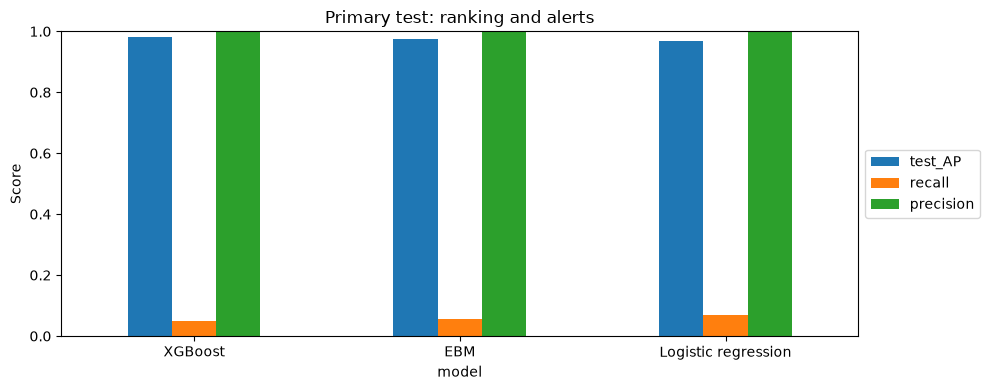

Sensitivity check: each model ranks the same number of flows for review (10% of this test population).


,model,review_budget,alerts,attack_labeled_alerts,normal_labeled_alerts,missed_attacks,precision,recall,f1,false_positive_rate
0,Logistic regression,7379,7379,7376,3,30887,0.9996,0.1928,0.3232,0.0001
1,XGBoost,7379,7379,7379,0,30884,1.0000,0.1928,0.3233,0.0000
2,EBM,7379,7379,7379,0,30884,1.0000,0.1928,0.3233,0.0000


In [12]:
test_scores = {
    'Logistic regression': logistic.predict_proba(Z_test)[:, 1],
    'XGBoost': xgboost.predict_proba(Z_test)[:, 1],
    'EBM': ebm.predict_proba(X_test)[:, 1],
}
model_alerts = {name: score >= model_cutoffs[name] for name, score in test_scores.items()}
model_table = pd.DataFrame([
    {'model': name, 'test_AP': average_precision_score(y_test, score),
     'test_ROC_AUC': roc_auc_score(y_test, score),
     'test_Brier': brier_score_loss(y_test, score),
     **alert_metrics(y_test, model_alerts[name])}
    for name, score in test_scores.items()
]).sort_values('test_AP', ascending=False)
display(model_table.round(4))
ax = model_table.set_index('model')[['test_AP', 'recall', 'precision']].plot(
    kind='bar', figsize=(10, 4), ylim=(0, 1), title='Primary test: ranking and alerts')
ax.set_ylabel('Score')
plt.xticks(rotation=0)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

def top_n_alerts(scores, count):
    scores = np.asarray(scores)
    count = min(max(int(count), 0), len(scores))
    selected = np.zeros(len(scores), dtype=bool)
    if count:
        selected[np.argsort(scores, kind='stable')[-count:]] = True
    return selected

budget = round(len(test) * 0.10)
budget_table = pd.DataFrame([
    {'model': name, 'review_budget': budget,
     **alert_metrics(y_test, top_n_alerts(score, budget))}
    for name, score in test_scores.items()
])
print('Sensitivity check: each model ranks the same number of flows for review (10% of this test population).')
display(budget_table.round(4))


## 13. Compare the selected classifier with standalone track alerts

A track is useful as an additional alert source only if the extra attack coverage justifies the extra normal-labeled flows sent for review. Because the frozen model cutoff and the rule union produce different queue sizes, we compare them at the **same number of alerts**: the selected model ranks as many flows as the rule union alerts. We then inspect what each track would add to that equally sized model queue. The simple OR union is a **diagnostic comparison**, not an adopted alert policy.


In [13]:
equal_budget = int(track_alerts['Rules'].sum())
equal_budget_model_alerts = top_n_alerts(test_scores[selected_name], equal_budget)
selected_alerts = equal_budget_model_alerts
equal_budget_cutoff = float(np.min(test_scores[selected_name][selected_alerts]))
print('Rules and equal-budget model each alert:', equal_budget, 'flows')
print('Score at the equal-budget queue boundary:', round(equal_budget_cutoff, 4))
display(pd.DataFrame([
    {'source': 'Rules', **alert_metrics(y_test, track_alerts['Rules'])},
    {'source': selected_name + ' at rule budget', **alert_metrics(y_test, equal_budget_model_alerts)},
]).round(4))
comparison = []
for name, track in track_alerts.items():
    extra = np.asarray(track, dtype=bool) & ~equal_budget_model_alerts
    combined = equal_budget_model_alerts | np.asarray(track, dtype=bool)
    comparison.append({
        'added_track': name,
        'extra_attack_labeled': int((extra & y_test.eq(1).to_numpy()).sum()),
        'extra_normal_labeled': int((extra & y_test.eq(0).to_numpy()).sum()),
        'combined_alerts': int(combined.sum()),
        'combined_recall': recall_score(y_test, combined),
    })
display(pd.DataFrame(comparison).round(4))


Rules and equal-budget model each alert: 27973 flows
Score at the equal-budget queue boundary: 0.9663


,source,alerts,attack_labeled_alerts,normal_labeled_alerts,missed_attacks,precision,recall,f1,false_positive_rate
0,Rules,27973,22578,5395,15685,0.8071,0.5901,0.6817,0.1519
1,XGBoost at rule budget,27973,27899,74,10364,0.9974,0.7291,0.8424,0.0021


,added_track,extra_attack_labeled,extra_normal_labeled,combined_alerts,combined_recall
0,Rules,1626,5373,34972,0.7716
1,Isolation Forest,857,1830,30660,0.7515
2,Connection concentration,0,0,27973,0.7291


## 14. Audit missed attack categories

The generated attack category is used **after** scoring to see where the selected model misses at the same alert count as the rule union. It was never a feature or a threshold input. This audit helps explain coverage gaps, but categories in this controlled dataset do not represent all real attacker behavior.


In [14]:
missed = test.loc[y_test.eq(1).to_numpy() & ~selected_alerts]
category_audit = test.loc[test.label.eq(1), 'attack_cat'].value_counts().rename('attack_flows').to_frame()
category_audit['missed'] = missed.attack_cat.value_counts().reindex(category_audit.index, fill_value=0)
category_audit['recall'] = 1 - category_audit['missed'] / category_audit['attack_flows']
display(category_audit.sort_values('missed', ascending=False).round(4))


,attack_flows,missed,recall
attack_cat,,,
Fuzzers,5801,4747,0.1817
Exploits,9330,2607,0.7206
Reconnaissance,2358,1619,0.3134
DoS,2085,694,0.6671
Generic,17149,313,0.9817
Shellcode,365,238,0.3479
Analysis,552,71,0.8714
Backdoor,579,60,0.8964
Worms,44,15,0.6591


## 15. Explain global and one local score

Global charts show which inputs each trained model relies on. For one attack-labeled test flow missed by the selected model at the rule-matched alert budget (or the first attack-labeled flow if none was missed), local contributions show how the model formed its score. These are **model explanations**, not proof that a feature caused an attack.


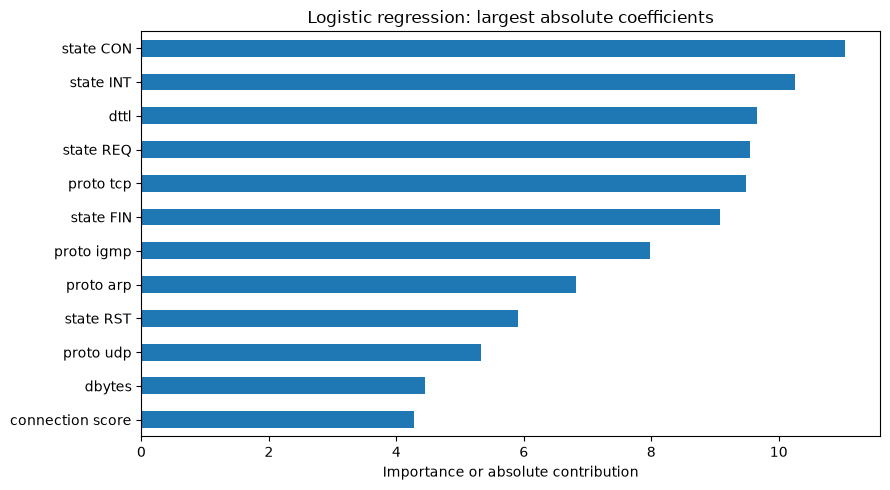

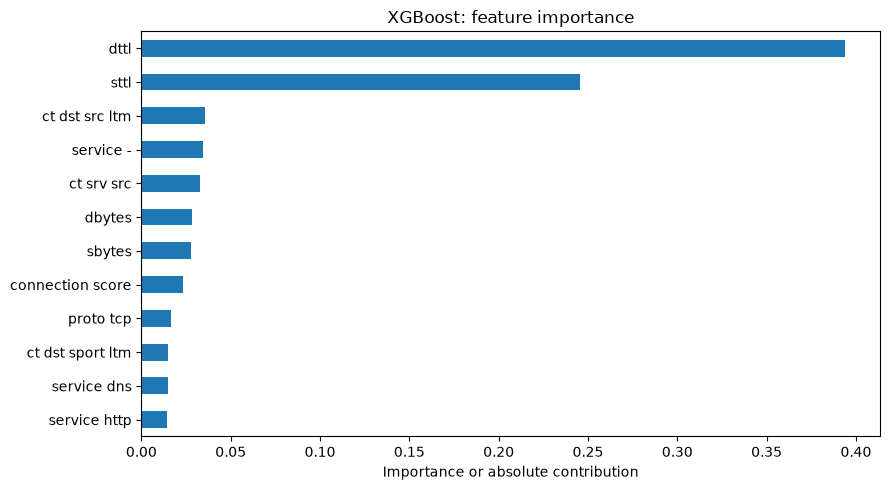

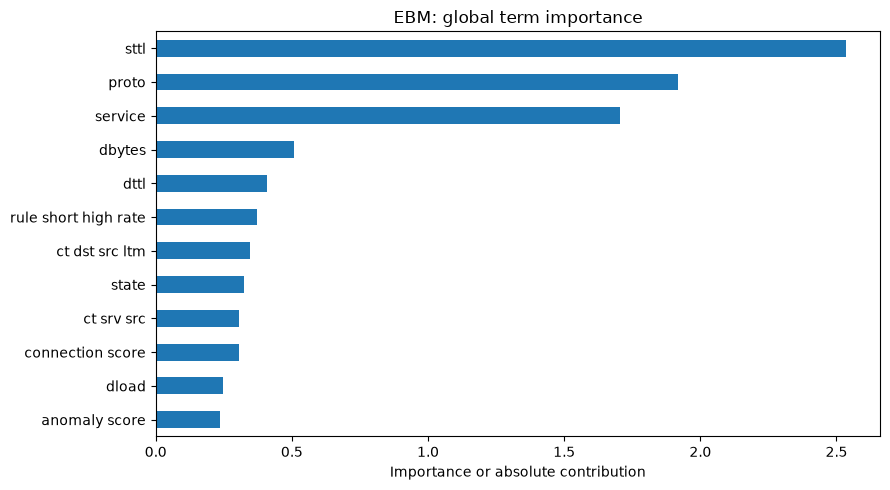

Example test row: 239 attack category: Exploits selected-model score: 0.9192
Equal-budget queue boundary: 0.9663
Selected-model alert: False


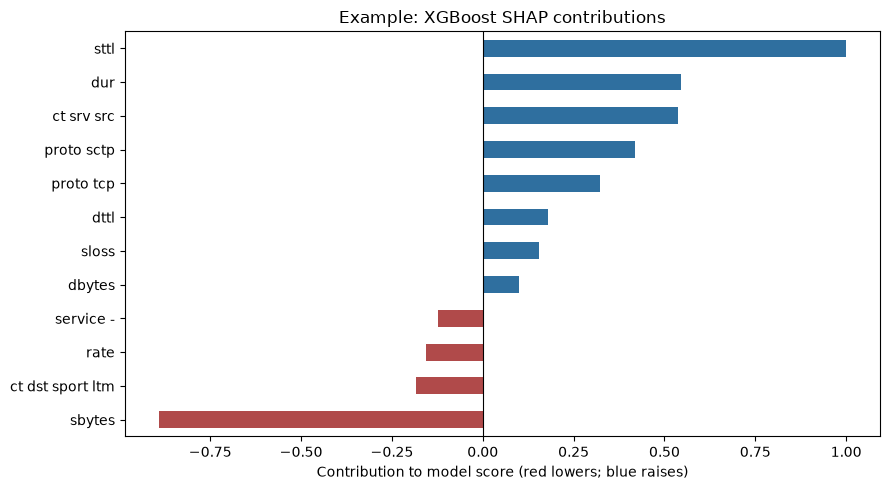

In [15]:
def top_bar(names, values, title, n=12):
    names = [str(name).replace('numeric__', '').replace('categorical__', '').replace('_', ' ') for name in names]
    series = pd.Series(values, index=names).sort_values(ascending=False).head(n).sort_values()
    ax = series.plot(kind='barh', figsize=(9, 5), title=title)
    ax.set_xlabel('Importance or absolute contribution')
    plt.tight_layout()
    plt.show()

def local_bar(names, values, title, n=12):
    names = [str(name).replace('numeric__', '').replace('categorical__', '').replace('_', ' ') for name in names]
    series = pd.Series(values, index=names)
    series = series.iloc[np.argsort(np.abs(series.to_numpy()))[-n:]].sort_values()
    colors = ['#b04a4a' if value < 0 else '#2f6f9f' for value in series]
    ax = series.plot(kind='barh', figsize=(9, 5), color=colors, title=title)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Contribution to model score (red lowers; blue raises)')
    plt.tight_layout()
    plt.show()

logistic_importance = np.abs(logistic.coef_[0])
top_bar(encoded_names, logistic_importance, 'Logistic regression: largest absolute coefficients')
top_bar(encoded_names, xgboost.feature_importances_, 'XGBoost: feature importance')
top_bar(ebm.term_names_, ebm.term_importances(), 'EBM: global term importance')

missed_positions = np.flatnonzero(y_test.eq(1).to_numpy() & ~selected_alerts)
example_position = int(missed_positions[0]) if len(missed_positions) else int(np.flatnonzero(y_test.eq(1).to_numpy())[0])
example = test.iloc[example_position]
print('Example test row:', example_position, 'attack category:', example.attack_cat,
      'selected-model score:', round(float(test_scores[selected_name][example_position]), 4))
print('Equal-budget queue boundary:', round(equal_budget_cutoff, 4))
print('Selected-model alert:', bool(selected_alerts[example_position]))
if selected_name == 'Logistic regression':
    contribution = np.asarray(Z_test[example_position].multiply(logistic.coef_[0]).toarray()).ravel()
    local_bar(encoded_names, contribution, 'Example: logistic contributions')
elif selected_name == 'XGBoost':
    shap_row = xgboost.get_booster().predict(DMatrix(Z_test[example_position]), pred_contribs=True)[0]
    local_bar(encoded_names, shap_row[:-1], 'Example: XGBoost SHAP contributions')
else:
    local = ebm.explain_local(X_test.iloc[[example_position]]).data(0)
    local_bar(local['names'], local['scores'], 'Example: EBM contributions')


## 16. Interpretation

Read the measured findings in `docs/FINDINGS.md`. The primary limitations are the controlled cyber-range setting, attack-heavy class balance, repeated feature rows, and lack of timestamps in the supplied split files. The model comparison demonstrates training, evaluation, alert tradeoffs, and explanation on a public benchmark. It does not establish how the detector would perform on different networks or future traffic.
